Explained variance ratio of each component: [0.14767651 0.13058658 0.12143415 0.11847458 0.11574808 0.11336378
 0.1109304  0.10897294]
Number of components selected: 8
Total explained variance: 0.9671870162920284


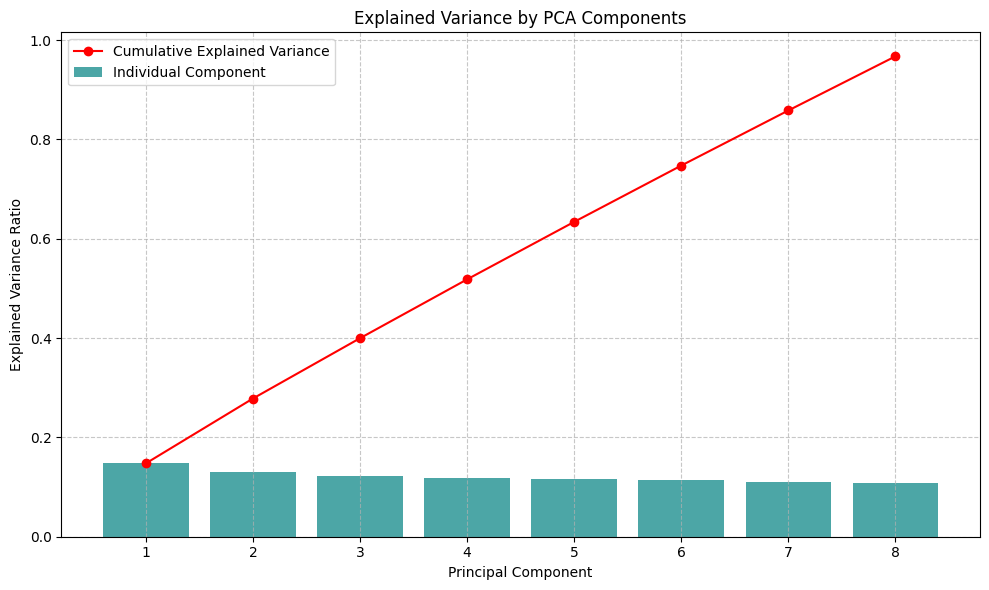

Head of PCA-transformed TRAIN dataset:
         PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
0 -0.025346  0.415288 -0.888507  0.291385 -0.113322  0.450057  0.491643   
1  0.010467  0.632269 -0.759007  0.163496  0.142807  0.367763  0.235976   
2  0.476770  0.653497  0.682484  0.720790  0.368317  0.174080 -0.258765   
3 -0.771273  0.548502 -0.390596 -0.365249  0.041606 -0.174154  0.526167   
4  0.546838 -0.657691 -0.983555 -0.195640 -0.226033  0.496606 -0.388184   

        PC8  LUNG_CANCER  
0  0.554199            1  
1 -0.780709            1  
2 -0.526771            1  
3 -0.020602            1  
4 -0.144647            1  

Head of PCA-transformed TEST dataset:
         PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
0  0.786952  0.536202  0.245797  0.332130  0.555055  0.019329  0.435060   
1  0.200820 -0.711273  0.523149 -0.403716  0.113353 -0.938527  0.206178   
2  0.741575  0.374888 -0.133524  0.053464 -0.178163  0.999526  0.521323   
3  0.24

In [2]:
from pathlib import Path
Path("results/outputs").mkdir(parents=True, exist_ok=True)
Path("results/eda_visualizations").mkdir(parents=True, exist_ok=True)

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Load already preprocessed datasets
train_df = pd.read_csv('data/train_selected_features.csv')
test_df = pd.read_csv('data/test_selected_features.csv')

# Separate features and target
X_train = train_df.drop('LUNG_CANCER', axis=1)
y_train = train_df['LUNG_CANCER']

X_test = test_df.drop('LUNG_CANCER', axis=1)
y_test = test_df['LUNG_CANCER']

# Apply PCA on training set only with dynamic component selection
pca = PCA(n_components=0.95, random_state=42)  # Retain 95% variance
X_train_pca = pca.fit_transform(X_train)
n_components = X_train_pca.shape[1]  # Actual number of components selected
X_test_pca = pca.transform(X_test)  # transform test set using the same PCA model

# Explained Variance
print("Explained variance ratio of each component:", pca.explained_variance_ratio_)
print(f"Number of components selected: {n_components}")
print("Total explained variance:", sum(pca.explained_variance_ratio_))

# Visualize Explained Variance
plt.figure(figsize=(10, 6))
plt.bar(range(1, n_components+1), pca.explained_variance_ratio_, alpha=0.7, color='teal')
plt.plot(range(1, n_components+1), pca.explained_variance_ratio_.cumsum(), marker='o', color='red')
plt.title('Explained Variance by PCA Components')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.xticks(range(1, n_components+1))
plt.legend(['Cumulative Explained Variance', 'Individual Component'], loc='best')
plt.grid(True, linestyle='--', alpha=0.7)  # Added grid for better readability
plt.tight_layout()
plt.savefig('results/eda_visualizations/pca_explained_variance.png')
plt.show()

# Create DataFrames with PCA components + target
pc_columns = [f'PC{i+1}' for i in range(n_components)]
train_pca_df = pd.concat([pd.DataFrame(X_train_pca, columns=pc_columns), y_train.reset_index(drop=True)], axis=1)
test_pca_df = pd.concat([pd.DataFrame(X_test_pca, columns=pc_columns), y_test.reset_index(drop=True)], axis=1)

# Show head of PCA-transformed datasets
print("Head of PCA-transformed TRAIN dataset:\n", train_pca_df.head())
print("\nHead of PCA-transformed TEST dataset:\n", test_pca_df.head())

# Save PCA-transformed datasets
train_pca_df.to_csv('results/outputs/train_pca.csv', index=False)
test_pca_df.to_csv('results/outputs/test_pca.csv', index=False)
print("Saved PCA-transformed train and test datasets to '../results/outputs/'")